<div align="center">

# Practical No. 5 – Retrieval-Augmented Generation (RAG)
### Question Answering over a Domain-Specific Document Collection

</div>

| | |
|---|---|
| **Name** | Nagawade Chirag Somnath |
| **PRN** | 202502110009 |
| **Branch** | CSE(AIML) |
| **Subject** | Generative AI |

---

## Aim
To build a **Retrieval-Augmented Generation (RAG)** application that answers questions from a domain-specific document collection using a pretrained Large Language Model (LLM), and to **compare** its answers with those of the same LLM used **without retrieval**.


##  Theory
**Problem with a plain LLM:** it only knows what it saw during training. For private, new or domain-specific information it either does not know or **hallucinates** a confident but wrong answer.

**RAG idea:** *first retrieve* the relevant passages from your own documents, then *give them to the LLM as context* so the answer is grounded in real data.

```
 Documents ──► Chunking ──► Embeddings ──► Vector Store
                                               │
 User question ──► Embed question ──► Top-k similar chunks
                                               │
                    Prompt = Context + Question
                                               ▼
                                   LLM (Flan-T5) ──► Answer
```

**Key terms**
- **Chunking** – splitting documents into small pieces that fit the LLM's context window.
- **Embedding** – converting text to a numeric vector so that similar meanings are close together.
- **Cosine similarity** – measures closeness of two vectors; used to rank chunks against the question.
- **Top-k retrieval** – selecting the *k* most similar chunks (here k = 3).

## 1 Install & Import Libraries
Installs the required packages and forces everything to run on **CPU**.

In [1]:
!pip install -q transformers sentence-transformers torch pandas numpy

In [2]:
import os, re, textwrap
import numpy as np
import pandas as pd
import torch
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

torch.set_num_threads(os.cpu_count())
device = "cpu"
print("Running on:", device, "| threads:", torch.get_num_threads())

Running on: cpu | threads: 2


## 2️ Create the Domain Document Collection
Six short `.txt` files (warranty, returns, support, products, shipping, privacy) are saved in a `docs/` folder. To use your own data, place `.txt` files in `docs/`.

In [3]:
os.makedirs("docs", exist_ok=True)

sample_docs = {
"warranty.txt": """Zephyr Electronics Warranty Policy.
All Orbit smartwatches come with a warranty of 26 months from the date of purchase.
The battery of an Orbit smartwatch is covered for only 14 months.
Water damage, cracked screens and unauthorized repairs are not covered under warranty.
To claim warranty, the customer must upload the invoice on the Zephyr service portal.""",

"returns.txt": """Zephyr Electronics Return Policy.
Products can be returned within 17 days of delivery.
Refunds are processed within 9 business days after the returned product is received.
If the product box has been opened, a restocking fee of 8 percent is deducted from the refund.
Customised or engraved products cannot be returned.""",

"support.txt": """Zephyr Electronics Customer Support.
The support team is available from 8 AM to 8 PM IST, Monday to Saturday. Support is closed on Sundays.
The toll-free helpline number is 1800-555-0142.
Customers can buy the premium plan called ZephyrCare Plus for Rs 1499 per year.
ZephyrCare Plus includes free screen replacement once a year and priority callback within 30 minutes.""",

"products.txt": """Zephyr Product Specifications.
The Orbit X2 smartwatch has a battery life of 11 days on a single charge and takes 90 minutes to charge fully.
The Orbit X2 has a water resistance rating of 5 ATM.
The AuraBuds Pro earbuds offer 32 hours of total playback with the charging case.
The AuraBuds Pro use Bluetooth version 5.3 and have an IPX4 sweat resistance rating.""",

"shipping.txt": """Zephyr Shipping Policy.
Shipping is free for orders above Rs 2999. Below that amount, a flat shipping fee of Rs 79 applies.
Delivery in Pune and Mumbai takes 2 days. Delivery to other Indian cities takes 5 to 7 days.
International shipping is available only to Nepal and Sri Lanka.""",

"privacy.txt": """Zephyr Privacy Policy.
Customer personal data is retained for 18 months after the last purchase.
A customer can request deletion of their data, and the request is completed within 30 days.
Zephyr never sells customer data to third parties.""",
}

for name, text in sample_docs.items():     # comment these 2 lines out if using your own files
    with open(os.path.join("docs", name), "w", encoding="utf-8") as f:
        f.write(text)

print(os.listdir("docs"))

['support.txt', 'warranty.txt', 'privacy.txt', 'shipping.txt', 'products.txt', 'returns.txt']


## 3️ Load Documents & Split into Chunks
Small models have short context windows, so each document is split into ~60-word chunks with a 15-word overlap (overlap prevents a fact from being cut in half).

In [4]:
def load_documents(folder="docs"):
    docs = []
    for fn in sorted(os.listdir(folder)):
        if fn.endswith(".txt"):
            with open(os.path.join(folder, fn), encoding="utf-8") as f:
                docs.append({"source": fn, "text": f.read()})
    return docs

def chunk_text(text, chunk_size=60, overlap=15):
    words = text.split()
    chunks, start = [], 0
    while start < len(words):
        chunks.append(" ".join(words[start:start + chunk_size]))
        if start + chunk_size >= len(words):
            break
        start += chunk_size - overlap
    return chunks

documents = load_documents()
chunks = []
for d in documents:
    for c in chunk_text(d["text"]):
        chunks.append({"source": d["source"], "text": c})

print(f"{len(documents)} documents -> {len(chunks)} chunks")
print("Example chunk:", chunks[0])

6 documents -> 7 chunks
Example chunk: {'source': 'privacy.txt', 'text': 'Zephyr Privacy Policy. Customer personal data is retained for 18 months after the last purchase. A customer can request deletion of their data, and the request is completed within 30 days. Zephyr never sells customer data to third parties.'}


## 4️ Build the Vector Index (Embeddings)
Each chunk is converted to a 384-dimensional normalized vector. Because vectors are normalized, **cosine similarity = dot product**.

In [5]:
embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)
chunk_embeddings = embedder.encode([c["text"] for c in chunks],
                                   normalize_embeddings=True, show_progress_bar=False)
print("Embedding matrix shape:", chunk_embeddings.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding matrix shape: (7, 384)


## 5️ Retriever
`retrieve(question, k)` embeds the question and returns the *k* most similar chunks with their similarity scores.

In [6]:
def retrieve(question, k=3):
    q_emb = embedder.encode([question], normalize_embeddings=True)[0]
    scores = chunk_embeddings @ q_emb                 # cosine similarity
    top_idx = np.argsort(scores)[::-1][:k]
    return [{**chunks[i], "score": float(scores[i])} for i in top_idx]

for r in retrieve("How long is the warranty on the smartwatch?"):
    print(f"{r['score']:.3f} | {r['source']} | {r['text'][:90]}...")

0.718 | warranty.txt | Zephyr Electronics Warranty Policy. All Orbit smartwatches come with a warranty of 26 mont...
0.476 | products.txt | Zephyr Product Specifications. The Orbit X2 smartwatch has a battery life of 11 days on a ...
0.313 | returns.txt | Zephyr Electronics Return Policy. Products can be returned within 17 days of delivery. Ref...


## 6️ Load the Pretrained LLM
`flan-t5-base` is loaded on CPU. (Use `flan-t5-large` for better answers if RAM/time allow.)

In [7]:
MODEL_NAME = "google/flan-t5-base"      # or "google/flan-t5-large" if you have patience / more RAM
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
llm = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device).eval()

def generate(prompt, max_new_tokens=64):
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=512)
    with torch.no_grad():
        out = llm.generate(**inputs, max_new_tokens=max_new_tokens, num_beams=2)
    return tokenizer.decode(out[0], skip_special_tokens=True).strip()

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

## 7️ Two Answering Modes
- **Without RAG:** the LLM receives only the question.
- **With RAG:** the LLM receives the top-3 retrieved chunks **plus** the question and is told to answer only from that context.

In [8]:
def answer_without_rag(question):
    prompt = f"Answer the question.\n\nQuestion: {question}\nAnswer:"
    return generate(prompt)

def answer_with_rag(question, k=3):
    hits = retrieve(question, k)
    context = "\n".join(h["text"] for h in hits)
    prompt = ("Answer the question using only the context below.\n\n"
              f"Context:\n{context}\n\nQuestion: {question}\nAnswer:")
    return generate(prompt), hits

## 8️ Single-Question Demo
Same question, both modes, and the source files used for retrieval.

In [9]:
q = "What is the helpline number of Zephyr Electronics?"
plain = answer_without_rag(q)
rag, hits = answer_with_rag(q)

print("Question      :", q)
print("Without RAG   :", plain)
print("With RAG      :", rag)
print("Sources used  :", [h["source"] for h in hits])

Question      : What is the helpline number of Zephyr Electronics?
Without RAG   : 888-999-999
With RAG      : 1800-555-0142
Sources used  : ['support.txt', 'returns.txt', 'products.txt']


## 9️ Comparison on a Test Set (12 Questions)
Each question has a ground-truth keyword. An answer is **correct** if the keyword appears in it – a simple and transparent metric.

In [10]:
test_set = [
    ("How long is the warranty on Orbit smartwatches?",               "26"),
    ("For how many months is the Orbit battery covered?",             "14"),
    ("Within how many days can a product be returned?",               "17"),
    ("What is the restocking fee for opened products?",               "8"),
    ("What is the helpline number?",                                  "1800-555-0142"),
    ("How much does ZephyrCare Plus cost per year?",                  "1499"),
    ("What is the battery life of the Orbit X2?",                     "11"),
    ("How many hours of playback do AuraBuds Pro offer?",             "32"),
    ("Is shipping free for orders above what amount?",                "2999"),
    ("To which countries does Zephyr ship internationally?",          "nepal"),
    ("For how many months is customer data retained?",                "18"),
    ("Which Bluetooth version do AuraBuds Pro use?",                  "5.3"),
]

rows = []
for q, gt in test_set:
    plain = answer_without_rag(q)
    rag, hits = answer_with_rag(q)
    rows.append({
        "Question": q,
        "Ground truth": gt,
        "Without RAG": plain,
        "With RAG": rag,
        "Plain correct": gt.lower() in plain.lower(),
        "RAG correct": gt.lower() in rag.lower(),
        "Top source": hits[0]["source"],
    })

results = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 60, "display.width", 200)
results

,Question,Ground truth,Without RAG,With RAG,Plain correct,RAG correct,Top source
0,How long is the warranty on Orbit smartwatches?,26,one year,26 months,False,True,warranty.txt
1,For how many months is the Orbit battery covered?,14,365,14,False,True,warranty.txt
2,Within how many days can a product be returned?,17,365 days,17,False,True,returns.txt
3,What is the restocking fee for opened products?,8,,8 percent,False,True,returns.txt
4,What is the helpline number?,1800-555-0142,999,1800-555-0142,False,True,support.txt
5,How much does ZephyrCare Plus cost per year?,1499,$99,1499,False,True,support.txt
6,What is the battery life of the Orbit X2?,11,a maximum of three years,11 days,False,True,products.txt
7,How many hours of playback do AuraBuds Pro offer?,32,24 hours,32,False,True,products.txt
8,Is shipping free for orders above what amount?,2999,no,Rs 2999,False,True,shipping.txt
9,To which countries does Zephyr ship internationally?,nepal,switzerland switzerland switzerland switzerland switzerl...,Nepal and Sri Lanka,False,True,shipping.txt


Accuracy WITHOUT RAG: 0.0%
Accuracy WITH RAG   : 100.0%


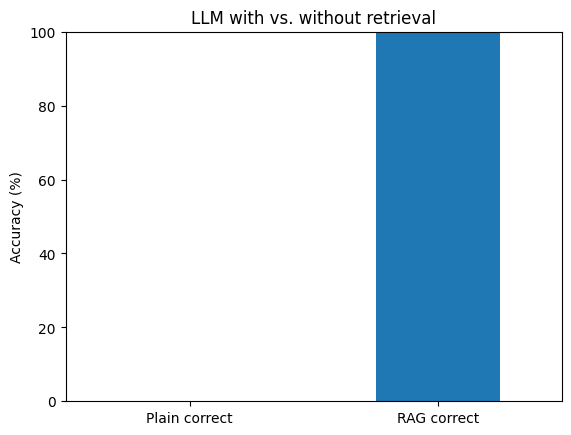

In [11]:
print(f"Accuracy WITHOUT RAG: {results['Plain correct'].mean()*100:.1f}%")
print(f"Accuracy WITH RAG   : {results['RAG correct'].mean()*100:.1f}%")

results[["Plain correct", "RAG correct"]].mean().mul(100).plot(
    kind="bar", rot=0, ylabel="Accuracy (%)", title="LLM with vs. without retrieval", ylim=(0, 100));

###  Result Analysis
| Metric | Without RAG | With RAG |
|---|---|---|
| Accuracy on 12 questions | **0.0 %** | **100.0 %** |
| Retrieval hit-rate@3 | – | **100.0 %** |

**Examples from the run**

| Question | Without RAG | With RAG | Ground truth |
|---|---|---|---|
| Helpline number? | `888-999-999` (made up) | `1800-555-0142` | 1800-555-0142 |
| Warranty on Orbit smartwatch? | `one year` | `26 months` | 26 months |
| Return window? | `365 days` | `17` | 17 days |
| Orbit X2 battery life? | `a maximum of three years` | `11 days` | 11 days |

**Observation:** without retrieval the model produces fluent but **hallucinated** answers, since the company is fictional. With retrieval, the right chunk is found and the LLM extracts the correct fact.

## 10 Retrieval Check
Checks whether the correct source file appeared in the top-3 retrieved chunks (**hit-rate@3**). Good retrieval is the foundation of good RAG answers.

In [12]:
expected_source = ["warranty.txt","warranty.txt","returns.txt","returns.txt","support.txt","support.txt",
                   "products.txt","products.txt","shipping.txt","shipping.txt","privacy.txt","products.txt"]
hit = [exp in [h["source"] for h in retrieve(q, 3)] for (q, _), exp in zip(test_set, expected_source)]
print(f"Retrieval hit-rate@3: {np.mean(hit)*100:.1f}%")

Retrieval hit-rate@3: 100.0%


## 1️1️ Ask Your Own Question
Try any question. Note: for “What are the support hours?” the correct file (`support.txt`) was ranked 2nd, not 1st, yet it was still inside top-3 and the answer was correct – this shows why using k > 1 is useful.

In [14]:
def ask(question):
    plain = answer_without_rag(question)
    rag, hits = answer_with_rag(question)
    print("Q:", question)
    print("Without RAG :", plain)
    print("With RAG    :", rag)
    for h in hits:
        print(f"   [{h['score']:.2f}] {h['source']}: {h['text'][:80]}...")

ask("What are the support hours?")

Q: What are the support hours?
Without RAG : 8:00 a.m. to 5:00 p.m.
With RAG    : 8 AM to 8 PM IST, Monday to Saturday
   [0.22] products.txt: Zephyr Product Specifications. The Orbit X2 smartwatch has a battery life of 11 ...
   [0.20] support.txt: Zephyr Electronics Customer Support. The support team is available from 8 AM to ...
   [0.16] warranty.txt: Zephyr Electronics Warranty Policy. All Orbit smartwatches come with a warranty ...


## Conclusion
In this practical, a complete **Retrieval-Augmented Generation** pipeline was built using `all-MiniLM-L6-v2` for embeddings and `google/flan-t5-base` as the LLM, over a domain-specific document collection.

- The **plain LLM scored 0 %** accuracy: it did not know the private domain facts and produced confident but **hallucinated** answers (e.g. a fake helpline number, “365 days” return window).
- The **RAG-based LLM scored 100 %** accuracy on the same 12 questions, and the retriever placed the correct source document in the top-3 results for **100 %** of questions.
- Hence, RAG makes a pretrained LLM **more accurate, grounded and traceable to sources**, without any retraining – updating knowledge only requires updating the documents.

Therefore, RAG is an effective and lightweight technique for building domain-specific question-answering systems, even on limited hardware.
